80 paires
(1024, 1280) (1024, 1280)


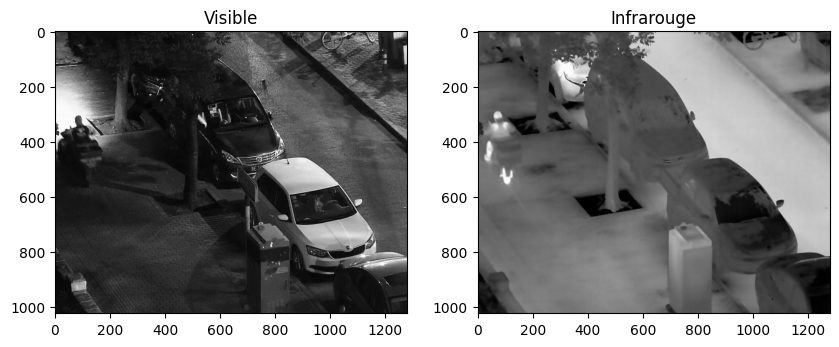

In [5]:
!pip -q install kornia opencv-python
!unzip -q LLVIP_sample.zip -d data

import os, cv2, numpy as np
import matplotlib.pyplot as plt

vis_dir, ir_dir = "data/visible", "data/infrared"
names = sorted(os.listdir(vis_dir))
print(len(names), "paires")

def load_pair(n):
    v = cv2.imread(f"{vis_dir}/{n}", cv2.IMREAD_GRAYSCALE)
    i = cv2.imread(f"{ir_dir}/{n}", cv2.IMREAD_GRAYSCALE)
    return v, i

v, i = load_pair(names[0])
print(v.shape, i.shape)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(v, cmap="gray"); ax[0].set_title("Visible")
ax[1].imshow(i, cmap="gray"); ax[1].set_title("Infrarouge")
plt.show()

In [6]:
rng = np.random.default_rng(0)

def random_homography(h, w, s=0.06):
    corners = np.float32([[0,0],[w,0],[w,h],[0,h]])
    dst = corners + rng.uniform(-s, s, (4,2)) * [w, h]
    return cv2.getPerspectiveTransform(corners, dst.astype(np.float32))

def corner_error(H_est, H_true_inv, h, w):
    c = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
    a = cv2.perspectiveTransform(c, H_est)
    b = cv2.perspectiveTransform(c, H_true_inv)
    return float(np.mean(np.linalg.norm(a - b, axis=2)))

clahe = cv2.createCLAHE(2.0, (8,8))
sift = cv2.SIFT_create(4000)
bf = cv2.BFMatcher()

def register_sift(ir_warp, vis):
    k1, d1 = sift.detectAndCompute(clahe.apply(ir_warp), None)
    k2, d2 = sift.detectAndCompute(clahe.apply(vis), None)
    if d1 is None or d2 is None or len(k1) < 8 or len(k2) < 8:
        return None
    m = bf.knnMatch(d1, d2, k=2)
    good = [a for a, b in (x for x in m if len(x) == 2) if a.distance < 0.8 * b.distance]
    if len(good) < 8:
        return None
    p1 = np.float32([k1[g.queryIdx].pt for g in good]).reshape(-1,1,2)
    p2 = np.float32([k2[g.trainIdx].pt for g in good]).reshape(-1,1,2)
    H, _ = cv2.findHomography(p1, p2, cv2.RANSAC, 3.0)
    return H

errors_sift = []
for n in names:
    vis, ir = load_pair(n)
    h, w = vis.shape
    H = random_homography(h, w)
    ir_warp = cv2.warpPerspective(ir, H, (w, h))
    H_est = register_sift(ir_warp, vis)
    errors_sift.append(np.inf if H_est is None else corner_error(H_est, np.linalg.inv(H), h, w))

e = np.array(errors_sift)
print("Taux de réussite (< 3 px) :", np.mean(e < 3))
print("Erreur médiane (échecs exclus) :", np.median(e[np.isfinite(e)]))

Taux de réussite (< 3 px) : 0.0
Erreur médiane (échecs exclus) : 873.5958557128906


In [7]:
rng = np.random.default_rng(1)
ok = []
for n in names[:20]:
    vis, _ = load_pair(n)
    h, w = vis.shape
    H = random_homography(h, w)
    vis_warp = cv2.warpPerspective(vis, H, (w, h))
    H_est = register_sift(vis_warp, vis)
    ok.append(H_est is not None and corner_error(H_est, np.linalg.inv(H), h, w) < 3)
print("Sanity check, réussite visible->visible :", np.mean(ok))

Sanity check, réussite visible->visible : 1.0


In [8]:
import torch
from kornia.feature import LoFTR

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)
loftr = LoFTR(pretrained="outdoor").to(device).eval()
S = np.diag([0.5, 0.5, 1.0])  # plein format -> 640x512

def to_t(img):
    small = cv2.resize(img, (640, 512))
    return torch.from_numpy(small).float()[None, None].to(device) / 255.

def register_loftr(ir_warp, vis):
    with torch.no_grad():
        out = loftr({"image0": to_t(ir_warp), "image1": to_t(vis)})
    p1 = out["keypoints0"].cpu().numpy().reshape(-1, 1, 2)
    p2 = out["keypoints1"].cpu().numpy().reshape(-1, 1, 2)
    if len(p1) < 8:
        return None
    H, _ = cv2.findHomography(p1, p2, cv2.RANSAC, 3.0)
    if H is None:
        return None
    return np.linalg.inv(S) @ H @ S  # retour au plein format

rng = np.random.default_rng(0)
err_sift, err_loftr = [], []
for n in names:
    vis, ir = load_pair(n)
    h, w = vis.shape
    H = random_homography(h, w)
    Hinv = np.linalg.inv(H)
    ir_warp = cv2.warpPerspective(ir, H, (w, h))
    for fn, store in [(register_sift, err_sift), (register_loftr, err_loftr)]:
        He = fn(ir_warp, vis)
        store.append(np.inf if He is None else corner_error(He, Hinv, h, w))

for name, e in [("SIFT", np.array(err_sift)), ("LoFTR", np.array(err_loftr))]:
    ok = e < 3
    print(f"{name}: réussite <3px = {ok.mean():.2f} | erreur médiane sur les réussites = "
          f"{np.median(e[ok]) if ok.any() else float('nan'):.2f} px")

cuda


Downloading: "https://huggingface.co/kornia/loftr/resolve/main/loftr_outdoor.ckpt" to /root/.cache/torch/hub/checkpoints/loftr_outdoor.ckpt
100%|██████████| 44.2M/44.2M [00:00<00:00, 62.7MB/s]


SIFT: réussite <3px = 0.00 | erreur médiane sur les réussites = nan px
LoFTR: réussite <3px = 0.00 | erreur médiane sur les réussites = nan px


In [9]:
for name, err in [("SIFT", err_sift), ("LoFTR", err_loftr)]:
    e = np.array(err)
    print(name, "- échecs complets :", int(np.isinf(e).sum()), "/", len(e))
    for t in [3, 5, 10, 20, 50]:
        print(f"   réussite <{t}px : {np.mean(e < t):.2f}")
    fin = e[np.isfinite(e)]
    if len(fin):
        print("   erreur médiane (hors échecs complets) :", round(float(np.median(fin)), 1), "px")

SIFT - échecs complets : 0 / 80
   réussite <3px : 0.00
   réussite <5px : 0.00
   réussite <10px : 0.01
   réussite <20px : 0.07
   réussite <50px : 0.11
   erreur médiane (hors échecs complets) : 873.6 px
LoFTR - échecs complets : 0 / 80
   réussite <3px : 0.00
   réussite <5px : 0.01
   réussite <10px : 0.06
   réussite <20px : 0.38
   réussite <50px : 0.70
   erreur médiane (hors échecs complets) : 26.9 px


In [10]:
rng = np.random.default_rng(1)
res = []
for n in names[:20]:
    vis, _ = load_pair(n)
    h, w = vis.shape
    H = random_homography(h, w)
    vw = cv2.warpPerspective(vis, H, (w, h))
    He = register_loftr(vw, vis)
    res.append(np.inf if He is None else corner_error(He, np.linalg.inv(H), h, w))
res = np.array(res)
print("LoFTR visible->visible : réussite <3px =", np.mean(res < 3), "| <10px =", np.mean(res < 10))

LoFTR visible->visible : réussite <3px = 1.0 | <10px = 1.0


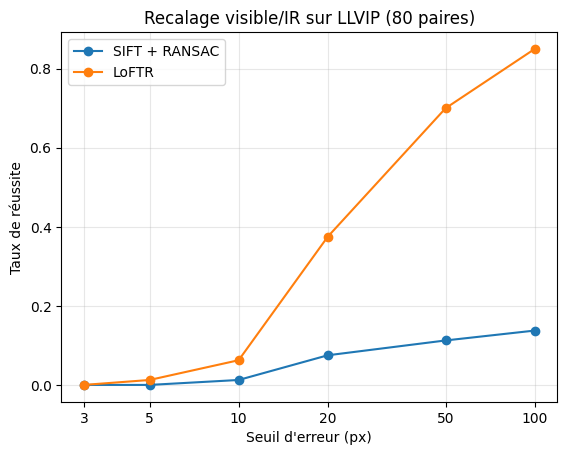

In [12]:
import matplotlib.pyplot as plt
ts = [3, 5, 10, 20, 50, 100]
for name, err in [("SIFT + RANSAC", err_sift), ("LoFTR", err_loftr)]:
    e = np.array(err)
    plt.plot(ts, [np.mean(e < t) for t in ts], marker="o", label=name)
plt.xlabel("Seuil d'erreur (px)"); plt.ylabel("Taux de réussite")
plt.xscale("log"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Recalage visible/IR sur LLVIP (80 paires)")
plt.xticks(ts, [str(t) for t in ts])
plt.minorticks_off()
plt.savefig("courbes.png", dpi=150, bbox_inches="tight"); plt.show()

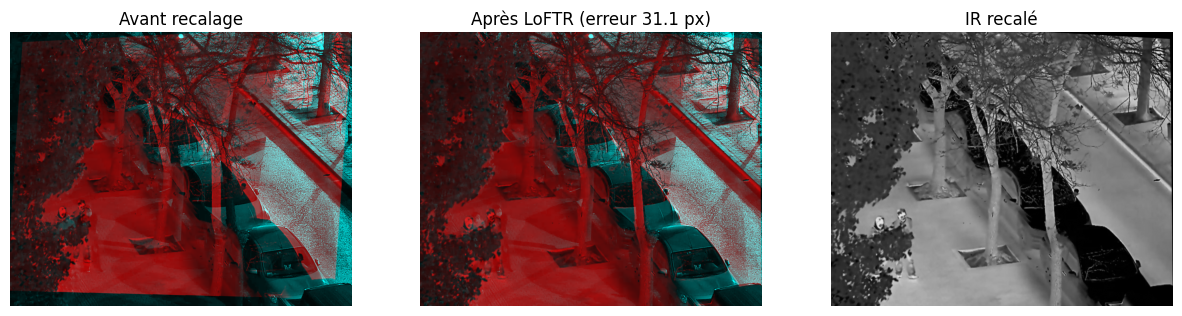

In [13]:
rng = np.random.default_rng(5)
order = np.argsort(err_loftr)
n = names[int(order[len(order)//2])]

vis, ir = load_pair(n)
h, w = vis.shape
H = random_homography(h, w)
ir_warp = cv2.warpPerspective(ir, H, (w, h))
He = register_loftr(ir_warp, vis)
ir_rec = cv2.warpPerspective(ir_warp, He, (w, h))
err = corner_error(He, np.linalg.inv(H), h, w)

vis_c = clahe.apply(vis)
def overlay(a, b):
    return np.dstack([a, b, b])  # a en rouge, b en cyan

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(overlay(ir_warp, vis_c)); ax[0].set_title("Avant recalage")
ax[1].imshow(overlay(ir_rec, vis_c)); ax[1].set_title(f"Après LoFTR (erreur {err:.1f} px)")
ax[2].imshow(ir_rec, cmap="gray"); ax[2].set_title("IR recalé")
for a in ax: a.axis("off")
plt.savefig("avant_apres.png", dpi=150, bbox_inches="tight"); plt.show()